In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
import os
from scipy.interpolate import InterpolatedUnivariateSpline as inspl

## Notepad para graficación básica de datos (ECs raspa)

In [2]:
# Leyendo archivos de datos
zheng = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\ecs\zheng.dat')
hu = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\ecs\hu.dat')
zhang = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\ecs\zhang.dat')
wu = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\ecs\wu.dat')
schmidt = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\ecs\schmidt.dat')
maul = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\ecs\maulDFT.dat')

In [3]:
# Transformando
zheng = np.transpose(zheng)
hu = np.transpose(hu)
zhang = np.transpose(zhang)
wu = np.transpose(wu)
schmidt = np.transpose(schmidt)
maul = np.transpose(maul)

DFT = [0.0, 11.038, 8.325, 0.943]
Bri = [0.0, 9.52, 6.87, 0.97]
#DFT[1]
maul

array([[ 0.   ,  0.1  ,  0.15 ,  0.2  ,  0.25 ,  0.3  ,  0.35 ,  0.4  ],
       [ 9.945, 10.04 , 10.043,  9.881,  9.616,  9.134,  8.946,  8.936],
       [ 8.643,  8.726,  8.78 ,  8.681,  8.493,  8.062,  7.924,  7.953],
       [ 0.791,  0.811,  0.737,  0.6  ,  0.488,  0.377,  0.252,  0.14 ]])

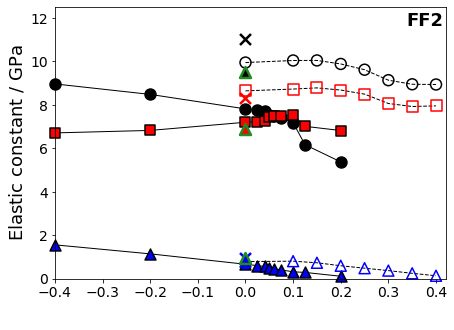

In [4]:
# Plotting FF
fig = plt.figure()
fig.set_size_inches(7.0, 5.0, forward=True)
plt.xlabel(r"Pressure, $P$ / $\mathrm{GPa}$", fontsize=18, color="white")
plt.ylabel(r"Elastic constant / $\mathrm{GPa}$", fontsize=18)

# Pressure, $P$ / $\mathrm{GPa}$ color="white"
# Elastic constant / $\mathrm{GPa}$ color="white"

plt.axis([-0.40, 0.42, 0, 12.5])
plt.xticks(np.arange(-0.40, 0.42, 0.1), fontsize=14)
plt.yticks(np.arange(0, 12.5, 2), fontsize=14)

# a[0], a[1], marker='o', color='red', edgecolor='black', linewidth=1, s=90, label='FF1', zorder=2
#plt.scatter(zhang[0], zhang[1], marker='o', color='black', edgecolor='black', linewidth=1, s=120, zorder=2, label='C11', clip_on=False)
#plt.scatter(zhang[0], zhang[2], marker='o', color='red', edgecolor='black', linewidth=1, s=120, zorder=2, label='C12', clip_on=False)
#plt.scatter(zhang[0], zhang[3], marker='o', color='blue', edgecolor='black', linewidth=1, s=120, zorder=2, label='C44', clip_on=False)

plt.scatter(hu[0], hu[1], marker='o', color='black', edgecolor='black', linewidth=1.5, s=120, zorder=2, clip_on=False)
plt.scatter(hu[0], hu[2], marker='s', color='red', edgecolor='black', linewidth=1.5, s=120, zorder=2, clip_on=False)
plt.scatter(hu[0], hu[3], marker='^', color='blue', edgecolor='black', linewidth=1.5, s=120, zorder=2, clip_on=False)

plt.scatter(maul[0], maul[1], marker='o', color='black', facecolors='none', edgecolor='black', linewidth=1.5, s=120, zorder=2, clip_on=False)
plt.scatter(maul[0], maul[2], marker='s', color='red', facecolors='none', edgecolor='red', linewidth=1.5, s=120, zorder=2, clip_on=False)
plt.scatter(maul[0], maul[3], marker='^', color='blue', facecolors='none', edgecolor='blue', linewidth=1.5, s=120, zorder=2, clip_on=False)

plt.scatter(DFT[0], DFT[1], marker='x', facecolor='black', linewidth=2.5, s=120, zorder=3, label='C11 DFT (B3LYP)')
plt.scatter(DFT[0], DFT[2], marker='x', facecolor='red', linewidth=2.5, s=120, zorder=3, label='C12 DFT (B3LYP)')
plt.scatter(DFT[0], DFT[3], marker='x', facecolor='blue', linewidth=2.5, s=120, zorder=3, label='C44 DFT (B3LYP)')

plt.scatter(Bri[0], Bri[1], marker='^', color='black', edgecolor='forestgreen', linewidth=2.5, s=120, zorder=4, label='C11 Bri')
plt.scatter(Bri[0], Bri[2], marker='^', color='red', edgecolor='forestgreen', linewidth=2.5, s=120, zorder=4, label='C12 Bri')
plt.scatter(Bri[0], Bri[3], marker='^', color='blue', edgecolor='forestgreen', linewidth=2.5, s=120, zorder=4, label='C44 Bri')

plt.plot(hu[0], hu[1], linestyle='-', color='black', linewidth=1, zorder=1)
plt.plot(hu[0], hu[2], linestyle='-', color='black', linewidth=1, zorder=1)
plt.plot(hu[0], hu[3], linestyle='-', color='black', linewidth=1, zorder=1)

plt.plot(maul[0], maul[1], linestyle='--', color='black', linewidth=1, zorder=1)
plt.plot(maul[0], maul[2], linestyle='--', color='black', linewidth=1, zorder=1)
plt.plot(maul[0], maul[3], linestyle='--', color='black', linewidth=1, zorder=1)

plt.annotate('FF2', xy=(0.90, 0.93), xycoords='axes fraction', fontsize=18, fontweight='bold')
#plt.annotate('FF1', xy=(0.02, 0.03), xycoords='axes fraction', fontsize=18, fontweight='bold')

#plt.scatter(0, lammps_CG, clip_on=False, marker='s', color='red', edgecolor='black', linewidth=1.5, s=90, zorder=2, label='Serial CG w/box relax')
#plt.scatter(0, lammps_CG_2, clip_on=False, marker='s', color='orange', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Serial CG w/box relax')
#plt.scatter(0, lammps_iter, clip_on=False, marker='s', color='orange', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Alternating SD & CG w/box relax')
#plt.scatter(0, lammps_md, marker='s', clip_on=False, facecolors='none', edgecolor='red', linewidth=1.5, s=100, zorder=2)

#plt.legend(facecolor='white', fontsize=13.5, framealpha=1.0)
# plt.grid(True, linestyle='--')
#fig.savefig(r'C:\Users\20210015\Documents\ZIF8manu16June\images\ecs\TOC.png', bbox_inches='tight', dpi=500)
#fig.savefig(r'C:\Users\20210015\Documents\ZIF8manu16June\images\ecs\TOC.pdf', bbox_inches='tight')
fig.savefig(r'C:\Users\20210015\Documents\ZIF8_2ndSubmission\AFTER RESUBMISSION\Changes\Including experimental data\ECs\upd\hu_corr.pdf', bbox_inches='tight')
fig.savefig(r'C:\Users\20210015\Documents\ZIF8_2ndSubmission\AFTER RESUBMISSION\Changes\Including experimental data\ECs\upd\hu_corr.png', bbox_inches='tight', dpi=500)

plt.show()